In [1]:
import numpy as np
import scipy
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
import lattice
import kmc
import loading as ld
from matplotlib.ticker import MaxNLocator

this program run with <Kappa^2> = 0.54486
DONE LOADING LATTICE
[0.         0.00027417 0.00054835 0.00082252 0.0010967  0.00137087
 0.00164505 0.00191922 0.00219339 0.00246757 0.00274174 0.00301592
 0.00329009 0.00356427 0.00383844 0.00411261 0.00438679 0.00466096
 0.00493514 0.00520931 0.00548349 0.00575766 0.00603183 0.00630601
 0.00658018 0.00685436 0.00712853 0.00740271 0.00767688 0.00795105
 0.00822523 0.0084994  0.00877358 0.00904775 0.00932193 0.0095961
 0.00987027 0.01014445 0.01041862 0.0106928  0.01096697 0.01124115
 0.01151532 0.01178949 0.01206367 0.01233784 0.01261202 0.01288619
 0.01316037 0.01343454 0.01370871 0.01398289 0.01425706 0.01453124
 0.01480541 0.01507959 0.01535376 0.01562793 0.01590211 0.01617628
 0.01645046 0.01672463 0.01699881 0.01727298 0.01754715 0.01782133
 0.0180955  0.01836968 0.01864385 0.01891803 0.0191922  0.01946637
 0.01974055 0.02001472 0.0202889  0.02056307 0.02083725 0.02111142
 0.02138559 0.02165977 0.02193394 0.02220812 0.02248229 0.02275647


In [2]:
#Teste 

RF = 1.3
tau = 1
r0=1
n=10
L =  r0*np.array([n])
PBC = [0]
LOAD_FIXED_KAPPA= False
FIXED_KAPPA = 0.476#2/3
save = False
cutoff = r0
nrounds = 1
krot_dip = 0

syst = ld.System(save=save,RF=RF,tau=tau,r0=r0,cutoff=cutoff,L=L,LOAD_FIXED_KAPPA=LOAD_FIXED_KAPPA,FIXED_KAPPA=FIXED_KAPPA,n=n,PBC=PBC,krot_dip=krot_dip)
syst.make_lattice()
#results = Parallel(n_jobs=7,verbose=2)(delayed(kmc_run_fluor)(syst) for n in range(nrounds))
results = kmc.kmc_run_fluor(syst)

positions = results[4] #arrays das posições do éxciton na rede 
MSD = results[5] #MSD para cada tempo
time = results[6] #tempos 
x = [float(positions[i][0]) for i in range(len(positions))] #lista das posições no eixo x 
#out_dict = process_results(results,file_header="",dim=len(L),RF=RF,tau=tau,r0=r0,FIXED_KAPPA=FIXED_KAPPA)

  
print(positions)
print(MSD)
print(time)
print(len(positions), len(MSD), len(time))


this program run with <Kappa^2> = 1.16846
DONE LOADING LATTICE
[array([0, 0, 0]), array([-1.,  0.,  0.]), array([0., 0., 0.]), array([-1.,  0.,  0.]), array([-2.,  0.,  0.]), array([-1.,  0.,  0.]), array([-2.,  0.,  0.]), array([-1.,  0.,  0.]), array([0., 0., 0.]), array([-1.,  0.,  0.]), array([-2.,  0.,  0.]), array([-1.,  0.,  0.]), array([-2.,  0.,  0.]), array([-1.,  0.,  0.]), array([-2.,  0.,  0.]), array([-2.,  0.,  0.])]
[0, np.float64(1.0), np.float64(0.0), np.float64(1.0), np.float64(4.0), np.float64(1.0), np.float64(4.0), np.float64(1.0), np.float64(0.0), np.float64(1.0), np.float64(4.0), np.float64(1.0), np.float64(4.0), np.float64(1.0), np.float64(4.0), np.float64(4.0)]
[0, np.float64(0.12581932262596077), np.float64(0.15109254686699009), np.float64(0.27802969998895843), np.float64(0.3100401382801585), np.float64(0.39713406875214724), np.float64(0.4513859778524447), np.float64(0.46936587097224447), np.float64(0.47082918955697084), np.float64(0.781630270753802), np.float

In [3]:
#Parâmetros 

RF = 4
tau = 1
r0=1
n=10
L =  r0*np.array([n])
PBC = [0]
LOAD_FIXED_KAPPA= False
FIXED_KAPPA = 0.476#2/3
save = False
cutoff = r0
nrounds = 1000
krot_dip = 0

In [4]:

syst = ld.System(save=save,RF=RF,tau=tau,r0=r0,cutoff=cutoff,L=L,LOAD_FIXED_KAPPA=LOAD_FIXED_KAPPA,FIXED_KAPPA=FIXED_KAPPA,n=n,PBC=PBC,krot_dip=krot_dip)
syst.make_lattice()
results_geral = [kmc.kmc_run_fluor(syst) for n in range(nrounds)]

positions = [results_geral[i][4] for i in range(len(results_geral))]
T = [results_geral[i][6] for i in range(len(results_geral))]
T = [results_geral[i][6] for i in range(len(results_geral))]
MSD = [results_geral[i][5] for i in range(len(results_geral))]


this program run with <Kappa^2> = 0.61026
DONE LOADING LATTICE


In [6]:
# MSD médio 

T_max = 0.6
T_int = np.linspace(0, T_max, 500)
MSDs_int = []

for i in range(len(T)):
    T_i = T[i]
    MSD_i = MSD[i]
    MSD_int = np.interp(T_int, T_i, MSD_i)
    MSD_int[T_int > max(T_i)] = np.nan
    MSDs_int.append(MSD_int)

MSDs_int = np.array(MSDs_int)
MSD_mean = np.nanmean(MSDs_int, axis=0)

n_valid = np.sum(~np.isnan(MSDs_int), axis=0)

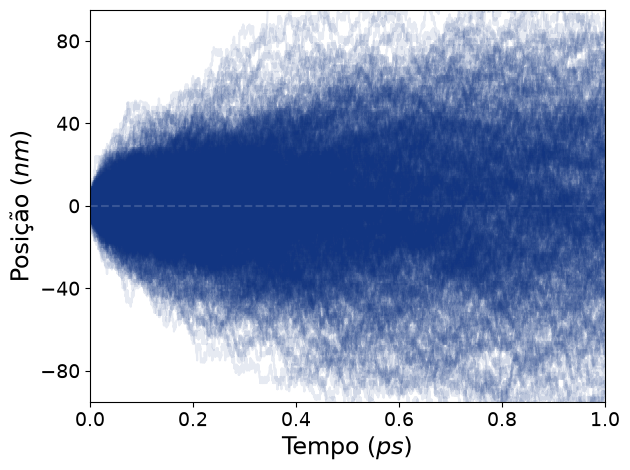

<Figure size 640x480 with 0 Axes>

In [7]:
#Gráfico difusão

plt.figure()
for i in range(len(positions)):
    positions_i = positions[i] #pega uma das trajetórias 
    T_i = T[i]
    x = [float(positions_i[n][0]) for n in range(len(positions_i))]
    plt.plot(T_i,x,c = "#123581", alpha = 0.1)


plt.xlabel(r"Tempo $(ps)$", fontsize = 17)
plt.ylabel(r"Posição $(nm)$", fontsize = 17)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlim(0,1)
plt.ylim(-95,95)

plt.gca().xaxis.set_major_locator(MaxNLocator(5))  # no máx. 5 ticks no eixo x
plt.gca().yaxis.set_major_locator(MaxNLocator(5))
plt.gca().axhline(0, color="#385595", linestyle='--')

plt.tight_layout()
plt.savefig(f"Imagens/Difusão.png")

plt.show()
plt.clf()

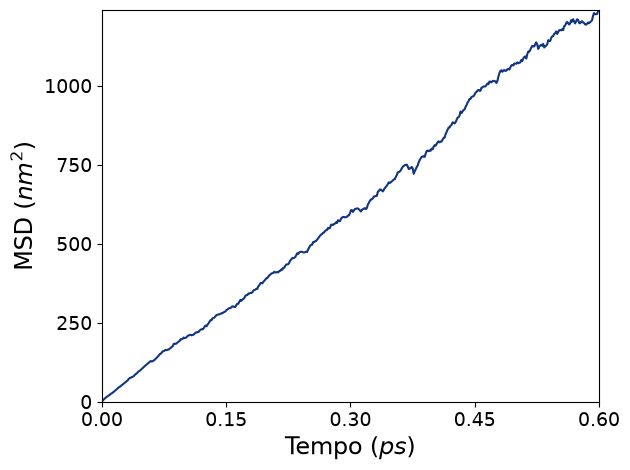

<Figure size 640x480 with 0 Axes>

In [8]:
#Gráfico MSD

plt.figure()
plt.plot(T_int,MSD_mean,c = "#123581")
plt.xlabel(r"Tempo $(ps)$", fontsize = 17)
plt.ylabel(r"MSD $(nm^2)$", fontsize = 17)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlim(0,T_max)
plt.ylim(0,MSD_mean[-1])

plt.gca().xaxis.set_major_locator(MaxNLocator(5))  # no máx. 5 ticks no eixo x
plt.gca().yaxis.set_major_locator(MaxNLocator(5))
#plt.gca().axhline(0, color="#123581", linestyle='--')

plt.tight_layout()
plt.savefig(f"Imagens/MSD.png")

plt.show()
plt.clf()


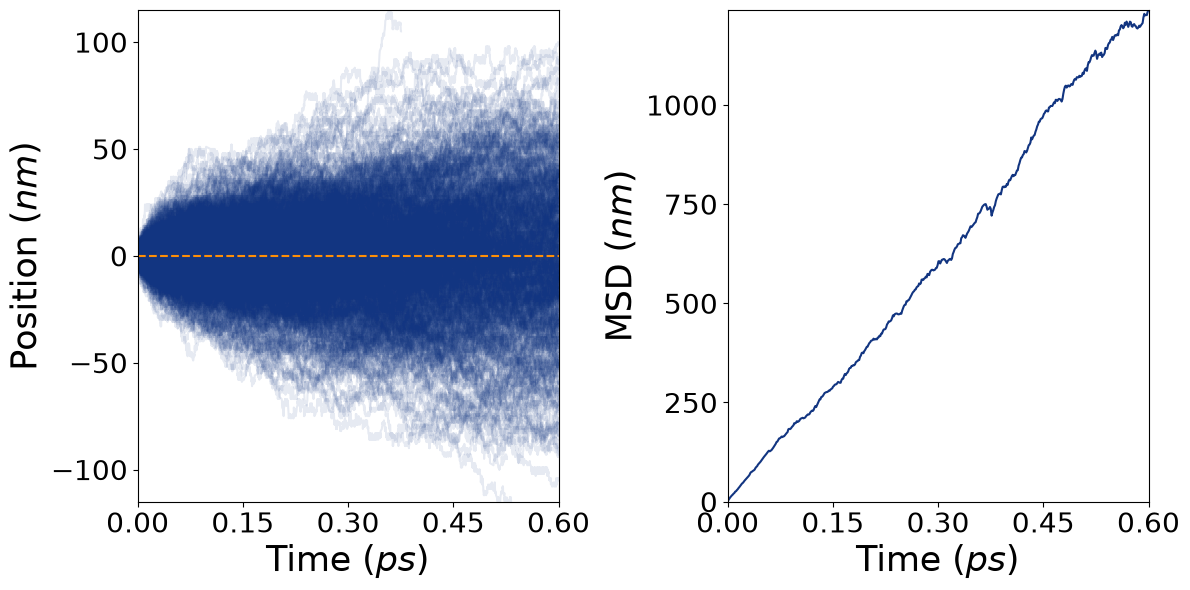

<Figure size 640x480 with 0 Axes>

In [10]:

fig, ax = plt.subplots(1, 2, figsize=(12, 6))

# Gráfico 1

ax[1].plot(T_int, MSD_mean,c = "#123581")
ax[1].set_xlabel(r"Time $(ps)$", fontsize = 25)
ax[1].set_ylabel(r"MSD $(nm)$", fontsize = 25)

ax[1].tick_params(axis="both", labelsize=20)
ax[1].set_xlim(0, T_max)
ax[1].set_ylim(0, MSD_mean[-1])

ax[1].xaxis.set_major_locator(MaxNLocator(5))
ax[1].yaxis.set_major_locator(MaxNLocator(5))


# Gráfico 2

for i in range(len(positions)):
    positions_i = positions[i] #pega uma das trajetórias 
    T_i = T[i]
    x = [float(positions_i[n][0]) for n in range(len(positions_i))]
    ax[0].plot(T_i,x,c = "#123581", alpha = 0.1)

ax[0].set_xlabel(r"Time $(ps)$", fontsize = 25)
ax[0].set_ylabel(r"Position $(nm)$", fontsize = 25)

ax[0].tick_params(axis="both", labelsize=20)
ax[0].set_xlim(0, 0.6)
ax[0].set_ylim(-115, 115)

ax[0].xaxis.set_major_locator(MaxNLocator(5))
ax[0].yaxis.set_major_locator(MaxNLocator(5))
ax[0].axhline(0, color="#FE8F07", linestyle="--")


plt.tight_layout()
plt.savefig(f"Imagens/Painel.png")

plt.show()
plt.clf()
